In [1]:
import gc
from scipy.io import loadmat
from probeinterface import Probe
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.extractors as se
import spikeinterface.sorters as ss
import spikeinterface.curation as scur
from spikeinterface.sortingcomponents.motion import estimate_motion, interpolate_motion

import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *

GEOM_PATH = rcp.resolve_probe_geom_path(PARAMS, REPO_ROOT, session_key=None)
NPRW_CFG     = PARAMS.probes.get("NPRW")
INTAN_STREAM = NPRW_CFG.get("neural_data_stream")
RADII        = (NPRW_CFG.get("local_radius_inner"), NPRW_CFG.get("local_radius_outer"))

global_job_kwargs = dict(n_jobs=PARAMS.parallel_jobs, chunk_duration=PARAMS.chunk)
si.set_global_job_kwargs(**global_job_kwargs)
job_kwargs = dict(n_jobs=-1, progress_bar=True, chunk_duration="1s")


# 
#     This script preprocesses the Fastigial Intan data.
#     Input:
#         .rhs files from Intan
#     Output:
#         Checkpoint after preprocessing
#         Checkpoint after thresholding and calculating MUA peak locations and firing rate
# 

In [2]:
# Load Geometry
mat_probe = loadmat(Path(GEOM_PATH))
intan_geom = {"x": mat_probe["xcoords"].ravel(), "y": mat_probe["ycoords"].ravel()}
assert intan_geom["x"].size == intan_geom["y"].size
if "chanMap0ind" not in mat_probe:
    raise ValueError("No 0-based chanmap in .mat geometry file.")
intan_probe_mapping = mat_probe["chanMap0ind"].ravel()
if intan_probe_mapping.size != intan_geom["x"].size:
    raise ValueError("device_index_0based length != #contacts")

nprw_probe = Probe(ndim=2)
nprw_probe.set_contacts(
    positions=np.c_[intan_geom["x"], intan_geom["y"]],
    shapes="square", shape_params={"width": 12.0},
)
nprw_probe.set_device_channel_indices(intan_probe_mapping)

In [3]:
nprw_probe.contact_positions

array([[  43,   20],
       [  11,   20],
       [  59,   40],
       [  27,   40],
       [  43,   60],
       [  11,   60],
       [  59,   80],
       [  27,   80],
       [  43,  100],
       [  11,  100],
       [  59,  120],
       [  27,  120],
       [  43,  140],
       [  11,  140],
       [  59,  160],
       [  27,  160],
       [  43,  180],
       [  11,  180],
       [  59,  200],
       [  27,  200],
       [  43,  220],
       [  11,  220],
       [  59,  240],
       [  27,  240],
       [  43,  260],
       [  11,  260],
       [  59,  280],
       [  27,  280],
       [  43,  300],
       [  11,  300],
       [  59,  320],
       [  27,  320],
       [  43,  340],
       [  11,  340],
       [  59,  360],
       [  27,  360],
       [  43,  380],
       [  11,  380],
       [  59,  400],
       [  27,  400],
       [  43,  420],
       [  11,  420],
       [  59,  440],
       [  27,  440],
       [  43,  460],
       [  11,  460],
       [  59,  480],
       [  27,

In [4]:
from probeinterface.plotting import plot_probe
plot_probe(nprw_probe)

plt.show()

/tmp/ipykernel_1602300/3085410695.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [5]:
# df = nprw_probe.to_dataframe()
# df

In [6]:
# nprw_probe.device_channel_indices

In [7]:
BIN_CKPT = OUT_BASE / "checkpoints" / "NPRW_binary"
BIN_CKPT.mkdir(parents=True, exist_ok=True)
STIM_STREAM = NPRW_CFG.get("stim_data_stream")

sess_name = "BL_closed_loop_STIM_003_250528_140952" # BL_closed_loop_STIM_003_250528_143802 and BL_closed_loop_STIM_003_250528_144603 are random stim
sess = INTAN_ROOT / sess_name
bin_path = BIN_CKPT / f"{sess.name}_neural.bin"

In [12]:
DRIFT_CKPT = OUT_BASE / "checkpoints" / "NPRW_drift"
SORT_CKPT  = OUT_BASE / "checkpoints" / "sorting_results" / f'{sess_name}_blanking'
DRIFT_CKPT.mkdir(parents=True, exist_ok=True)
SORT_CKPT.mkdir(parents=True, exist_ok=True)

In [9]:
# load Intan data
rec_raw = se.read_split_intan_files(sess, mode="concatenate", stream_name=INTAN_STREAM, use_names_as_ids=True)
rec_raw = spre.unsigned_to_signed(rec_raw)
rec_raw = rec_raw.set_probe(nprw_probe)
rec_raw = rcp.reorder_recording_to_geometry(rec_raw, intan_probe_mapping)
print(rec_raw)

ChannelSliceRecording: 128 channels - 30.0kHz - 1 segments - 8,706,816 samples 
                       290.23s (4.84 minutes) - int16 dtype - 2.08 GiB


In [10]:
import spikeinterface as si
import spikeinterface.preprocessing as spre

fs = 30000.0

rec_bp = spre.bandpass_filter(rec_raw, freq_min=float(PARAMS.highpass_hz), freq_max=float(PARAMS.lowpass_hz))
rec_bp = spre.astype(rec_bp, dtype="float32")
rec_cmr = spre.common_reference(rec_bp, reference="local", operator="median", local_radius=(RADII[0], RADII[1]))

print(rec_cmr)

CommonReferenceRecording: 128 channels - 30.0kHz - 1 segments - 8,706,816 samples 
                          290.23s (4.84 minutes) - float32 dtype - 4.15 GiB


noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (workers: 12 processes fork):   0%|          | 0/291 [00:00<?, ?it/s]

Cross correlation:   0%|          | 0/3 [00:00<?, ?it/s]

Solve:   0%|          | 0/2 [00:00<?, ?it/s]

interpolate_motion (InterpolateMotionRecording): 128 channels - 30.0kHz - 1 segments 
                    8,706,816 samples - 290.23s (4.84 minutes) - float32 dtype - 4.15 GiB

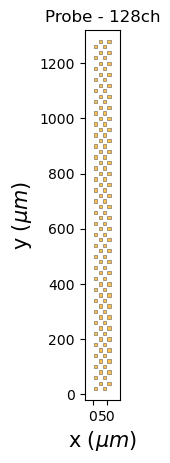

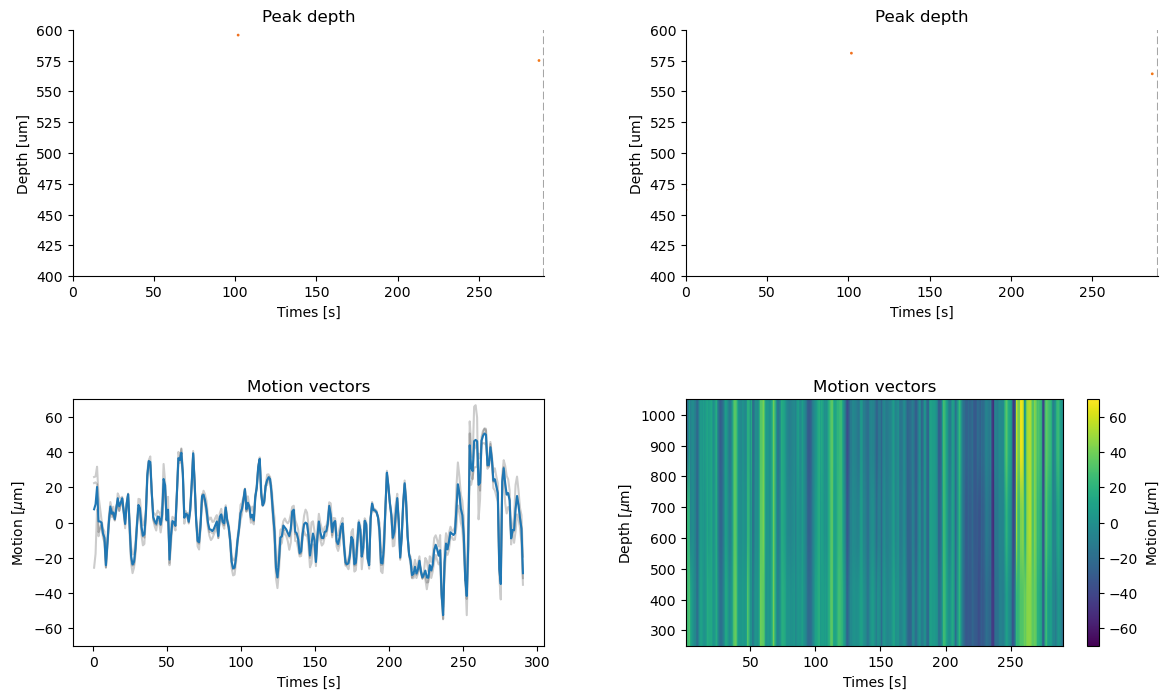

In [13]:
import matplotlib.pyplot as plt
plt.ion()
motion, motion_info = spre.compute_motion(
    rec_cmr, preset="dredge", folder=DRIFT_CKPT, output_motion_info=True, overwrite=True, **job_kwargs
)

import pickle

with open(SORT_CKPT / "motion_info.pkl", "wb") as f:
    pickle.dump(motion_info, f)

%matplotlib inline
from spikeinterface.widgets import plot_motion, plot_motion_info
fig = plt.figure(figsize=(14, 8))
plot_motion_info(
    motion_info, rec_cmr,
    figure=fig,
    depth_lim=(400, 600),
    color_amplitude=True,
    amplitude_cmap="inferno",
    scatter_decimate=10,
)

from spikeinterface.sortingcomponents.motion import interpolate_motion
interpolated_recording = interpolate_motion(
    recording=rec_cmr, motion=motion_info['motion'],
    border_mode="force_extrapolate"
)
interpolated_recording

In [14]:
RATES = PARAMS.NPRW_rate_est
ARTRMV_MS_BEFORE = float(RATES.get("remove_ms_before", 20.0))
ARTRMV_TAIL_MS   = float(RATES.get("remove_tail_ms_after", 20.0))

rec_artif_removed = interpolated_recording  # fallback
fs_nprw = rec_raw.get_sampling_frequency()
n_total = rec_raw.get_num_samples()

dur_ms = None

# Save preprocessed session
out_dir = NPRW_CKPT_ROOT / f"pp_local_{int(RADII[0])}_{int(RADII[1])}__interp_{sess.name}"
rcp.save_recording(interpolated_recording, out_dir)
print(f"[{sess.name}] saved artifact_removed -> {out_dir}")

write_binary_recording 
engine=process - n_jobs=12 - samples_per_chunk=120,000 - chunk_memory=58.59 MiB - total_memory=703.12 MiB - chunk_duration=4.00s


write_binary_recording (workers: 12 processes fork):   0%|          | 0/73 [00:00<?, ?it/s]

[BL_closed_loop_STIM_003_250528_140952] saved artifact_removed -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/NPRW/pp_local_30_150__interp_BL_closed_loop_STIM_003_250528_140952


In [15]:
# Save the corrected recording to disk so it's serializable for the sorter
saved_rec_path = SORT_CKPT / "rec_corrected_saved"
interpolated_recording_i16 = spre.astype(interpolated_recording, dtype="int16")
rec_corrected_saved = interpolated_recording_i16.save(
    folder=saved_rec_path,
    overwrite=True,
    **job_kwargs,
)
print(rec_corrected_saved)

write_binary_recording 
engine=process - n_jobs=12 - samples_per_chunk=30,000 - chunk_memory=7.32 MiB - total_memory=87.89 MiB - chunk_duration=1.00s


write_binary_recording (workers: 12 processes fork):   0%|          | 0/291 [00:00<?, ?it/s]

BinaryFolderRecording: 128 channels - 30.0kHz - 1 segments - 8,706,816 samples 
                       290.23s (4.84 minutes) - int16 dtype - 2.08 GiB


In [16]:
# Kilosort4
sorting = ss.run_sorter(
    sorter_name="kilosort4",
    recording=rec_artif_removed,
    folder=SORT_CKPT / "folder_KS4",
    remove_existing_folder=True,
    do_correction=False,
)
sorting = scur.remove_duplicated_spikes(sorting)
sorting = scur.remove_excess_spikes(sorting, rec_artif_removed)
sorting = scur.remove_redundant_units(sorting, align=False, remove_strategy="max_spikes")
sorting.save(folder=SORT_CKPT / "sorting_curated", overwrite=True)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:18<00:00, 18.25s/it]
/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/basesorting.py:384: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


NumpyFolder (NumpyFolderSorting): 164 units - 1 segments - 30.0kHz

In [17]:
sorting

UnitsSelectionSorting: 164 units - 1 segments - 30.0kHz

In [18]:
# Reload
# sorting = si.load(SORT_CKPT / "sorting_curated")

In [19]:
if 'analyzer_precuration' in dir():
    del analyzer_precuration
gc.collect()
import shutil, pathlib
folder = SORT_CKPT / "analyzer_blanking"
if folder.exists():
    shutil.rmtree(folder, ignore_errors=True)
    # force-remove anything left
    import subprocess
    subprocess.run(["rm", "-rf", str(folder)], check=True)

analyzer_precuration = si.create_sorting_analyzer(
    sorting, rec_artif_removed,
    format="binary_folder",
    folder=SORT_CKPT / "analyzer_blanking",
    overwrite=True,
    **job_kwargs,
)
analyzer_precuration.compute(
    [
        "random_spikes", "waveforms", "templates", "noise_levels",
        "spike_amplitudes", "unit_locations", "isi_histograms",
        "correlograms", "principal_components", "quality_metrics",
        "template_similarity",
    ],
    extension_params={
        "principal_components": {"n_components": 3, "mode": "by_channel_global", "whiten": True},
        "quality_metrics": {"metric_names": ["snr", "firing_rate", "rp_violation"],
            "metric_params": {"rp_violation": {"refractory_period_ms": 0.5}},},
    },
    **job_kwargs,
)

estimate_sparsity (workers: 12 processes fork):   0%|          | 0/291 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/basesorting.py:384: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


compute_waveforms (workers: 12 processes fork):   0%|          | 0/291 [00:00<?, ?it/s]

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

Fitting PCA:   0%|          | 0/164 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/164 [00:00<?, ?it/s]

/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/postprocessing/template_similarity.py:345: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  overlapping_ids = overlapping_j_list[i]


Compute : spike_amplitudes (workers: 12 processes fork):   0%|          | 0/291 [00:00<?, ?it/s]

In [22]:
import spikeinterface.curation as sc

qm = analyzer_precuration.get_extension("quality_metrics").get_data()
passing = qm.query("snr > 3.0 and firing_rate > 0.1 and rp_contamination < 0.2").index.tolist()
print(f"[global QM] {len(passing)}/{len(qm)} units pass SNR/FR/RP filter")
analyzer_precuration = analyzer_precuration.select_units(passing)

analyzer_precuration = analyzer_precuration.save_as(folder=SORT_CKPT / "analyzer_blanking_filtered", format="binary_folder")

[global QM] 54/54 units pass SNR/FR/RP filter


In [23]:
from spikeinterface.exporters import export_to_phy
export_to_phy(
    analyzer_precuration,
    output_folder=SORT_CKPT / "phy_blanking",
    remove_if_exists=True,
    **job_kwargs,
)
print(f"Phy export -> {SORT_CKPT / 'phy_blanking'}")


write_binary_recording (workers: 12 processes fork):   0%|          | 0/291 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/291 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_140952_blanking/phy_blanking/params.py
Phy export -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_140952_blanking/phy_blanking


[np.int64(145), np.int64(149)]

In [35]:
from spikeinterface.curation import compute_merge_unit_groups
merge_groups = compute_merge_unit_groups(analyzer_precuration, preset="slay", resolve_graph=True)
if merge_groups is not None and len(merge_groups) > 0:
    analyzer_clean = analyzer_precuration.merge_units(merge_unit_groups=[merge_groups[1]])
    print(f"[concat] {analyzer_clean.sorting.get_num_units()} units after SLAY merge")
else:
    print(f"[concat] no merges found, {analyzer_precuration.sorting.get_num_units()} units")

[concat] 53 units after SLAY merge


In [36]:
from scipy.io import savemat
spike_trains = {}
for uid in analyzer_clean.sorting.unit_ids:
    spike_trains[str(uid)] = analyzer_clean.sorting.get_unit_spike_train(uid, segment_index=0)
out_path = OUT_BASE / "checkpoints" / "sorting_results" / sess_name / "NPRW"
out_path.mkdir(parents=True, exist_ok=True)
savemat(out_path / "spike_trains.mat",
        {f"unit_{k}": v for k, v in spike_trains.items()} | {"fs": float(analyzer_clean.sorting.get_sampling_frequency())})

In [37]:
analyzer_clean

SortingAnalyzer: 128 channels - 53 units - 1 segments - memory - sparse - has recording
Loaded 11 extensions: random_spikes, waveforms, templates, noise_levels, unit_locations, isi_histograms, correlograms, principal_components, quality_metrics, template_similarity, spike_amplitudes

In [ ]:
#merge_units censor_ms to 5 samples, to remove duplicate spikes
merge_unit_groups = [[144, 150], [56, 18]]
remove_unit_ids = [36, 45, 54, 100, 108, 129]

analyzer_clean = analyzer_precuration.merge_units(
    merge_unit_groups=merge_unit_groups,
    censored_period_ms=0.5,
    merging_mode="soft"
)

# remove some units
analyzer_clean = analyzer_clean.remove_units(remove_unit_ids=remove_unit_ids, )

analyzer_clean = analyzer_clean.save_as(folder=SORT_CKPT / "analyzer_blanking_cleaned", format="binary_folder")

In [97]:
from scipy.io import savemat
spike_trains = {}
for uid in analyzer_clean.sorting.unit_ids:
    spike_trains[str(uid)] = analyzer_clean.sorting.get_unit_spike_train(uid, segment_index=0)
out_path = OUT_BASE / "checkpoints" / "sorting_results" / sess_name / "NPRW"
out_path.mkdir(parents=True, exist_ok=True)
savemat(out_path / "spike_trains.mat",
        {f"unit_{k}": v for k, v in spike_trains.items()} | {"fs": float(analyzer_clean.sorting.get_sampling_frequency())})

In [95]:
analyzer_clean

SortingAnalyzer: 128 channels - 120 units - 1 segments - memory - sparse - has recording
Loaded 11 extensions: random_spikes, waveforms, templates, noise_levels, unit_locations, isi_histograms, correlograms, principal_components, quality_metrics, template_similarity, spike_amplitudes